# Experiment 10 — K-Means Clustering for Data Segmentation

**Aim:** Use K-Means to group observations into segments using numeric features.

**Libraries:** pandas, NumPy, Matplotlib, and scikit-learn.

**Theory:** K-Means assigns points to centroids and minimizes within-cluster squared distance. It requires k, is scale-sensitive, and favors compact clusters.

**Dataset:** The local Iris CSV provides four measurements and species labels. Labels are reserved for the final comparison only.

## Procedure / Implementation
The following cells load the data, apply the stated method, produce outputs, and record observations.


Dataset source: datasets/iris.csv
Feature matrix shape: (150, 4)
Feature names: ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
Species counts (not used when fitting):
species
setosa        50
versicolor    50
virginica     50


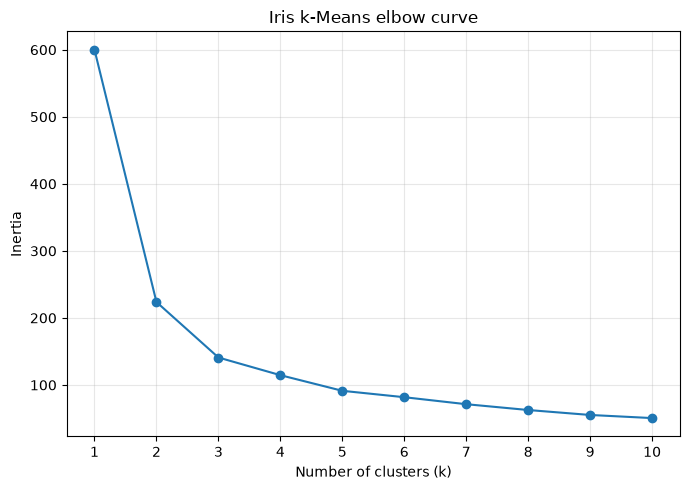

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.datasets import load_iris
from sklearn.metrics import adjusted_rand_score, silhouette_score
from sklearn.preprocessing import StandardScaler

SEED = 42
ROOT = Path.cwd()
if not (ROOT / 'datasets').is_dir():
    ROOT = ROOT.parent
FIGURES = ROOT / 'outputs' / 'figures'
RESULTS = ROOT / 'outputs' / 'results'
FIGURES.mkdir(parents=True, exist_ok=True)
RESULTS.mkdir(parents=True, exist_ok=True)
feature_names = ['sepal_length', 'sepal_width', 'petal_length', 'petal_width']
iris_path = ROOT / 'datasets' / 'iris.csv'
if iris_path.is_file():
    local = pd.read_csv(iris_path)
    if set(feature_names + ['species']).issubset(local.columns):
        X = local[feature_names].copy()
        species = local['species'].copy()
        data_source = 'datasets/iris.csv'
    else:
        print('Supplied Iris CSV schema is incompatible; using scikit-learn Iris data.')
        dataset = load_iris()
        X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
        feature_names = list(X.columns)
        species = pd.Series([dataset.target_names[index] for index in dataset.target], name='species')
        data_source = 'sklearn.datasets.load_iris()'
else:
    dataset = load_iris()
    X = pd.DataFrame(dataset.data, columns=dataset.feature_names)
    feature_names = list(X.columns)
    species = pd.Series([dataset.target_names[index] for index in dataset.target], name='species')
    data_source = 'sklearn.datasets.load_iris()'

print('Dataset source:', data_source)
print('Feature matrix shape:', X.shape)
print('Feature names:', list(X.columns))
print('Species counts (not used when fitting):')
print(species.value_counts().to_string())
X_scaled = StandardScaler().fit_transform(X)
inertia_rows = []
for cluster_count in range(1, 11):
    candidate = KMeans(n_clusters=cluster_count, random_state=SEED, n_init=10)
    candidate.fit(X_scaled)
    inertia_rows.append({'k': cluster_count, 'inertia': candidate.inertia_})
inertia_table = pd.DataFrame(inertia_rows)
fig, axis = plt.subplots(figsize=(7, 5))
axis.plot(inertia_table['k'], inertia_table['inertia'], marker='o')
axis.set(xticks=range(1, 11), xlabel='Number of clusters (k)', ylabel='Inertia', title='Iris k-Means elbow curve')
axis.grid(alpha=0.3)
fig.tight_layout()
fig.savefig(FIGURES / 'exp10_elbow_curve.png', dpi=150, bbox_inches='tight')
plt.show()

## Fit k = 3, evaluate and visualise

The elbow begins to flatten around k = 3. We use three clusters for the species comparison; the species column is not passed to `KMeans.fit`.

Chosen k: 3 (elbow curve bend and three species for comparison)
Silhouette score: 0.4590
Adjusted Rand index (comparison only): 0.6201
Contingency table (cluster numbers are arbitrary):
Cluster          0   1   2
Actual species            
setosa           0  50   0
versicolor      39   0  11
virginica       14   0  36


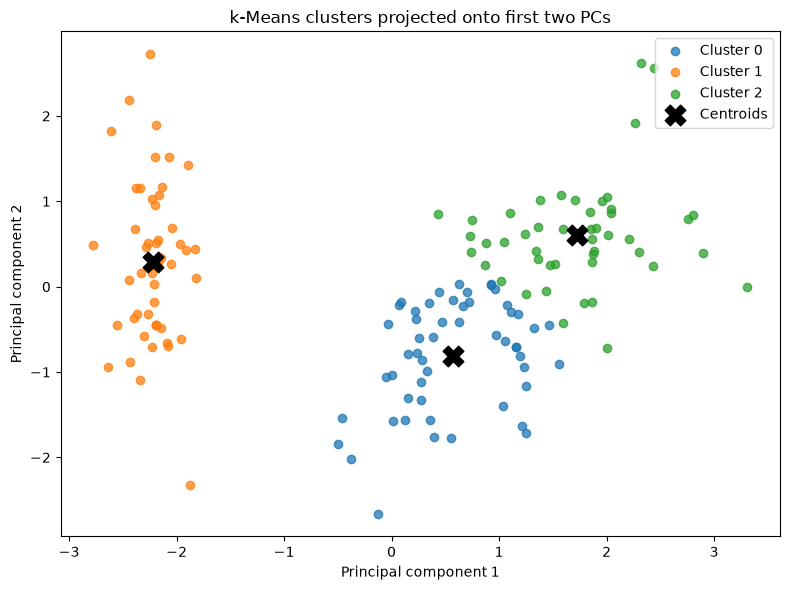

Conclusion: the silhouette score summarises separation; the contingency table and adjusted Rand index show how the unsupervised clusters correspond to the known species.


In [2]:
chosen_k = 3
kmeans = KMeans(n_clusters=chosen_k, random_state=SEED, n_init=10)
cluster_ids = kmeans.fit_predict(X_scaled)
silhouette = silhouette_score(X_scaled, cluster_ids)
ari = adjusted_rand_score(species, cluster_ids)
contingency = pd.crosstab(species, cluster_ids, rownames=['Actual species'], colnames=['Cluster'])
print(f'Chosen k: {chosen_k} (elbow curve bend and three species for comparison)')
print(f'Silhouette score: {silhouette:.4f}')
print(f'Adjusted Rand index (comparison only): {ari:.4f}')
print('Contingency table (cluster numbers are arbitrary):')
print(contingency.to_string())

pca = PCA(n_components=2, random_state=SEED)
points_2d = pca.fit_transform(X_scaled)
centroids_2d = pca.transform(kmeans.cluster_centers_)
fig, axis = plt.subplots(figsize=(8, 6))
for cluster_id in range(chosen_k):
    mask = cluster_ids == cluster_id
    axis.scatter(points_2d[mask, 0], points_2d[mask, 1], label=f'Cluster {cluster_id}', alpha=0.75)
axis.scatter(centroids_2d[:, 0], centroids_2d[:, 1], marker='X', s=220, c='black', label='Centroids')
axis.set(xlabel='Principal component 1', ylabel='Principal component 2', title='k-Means clusters projected onto first two PCs')
axis.legend()
fig.tight_layout()
fig.savefig(FIGURES / 'exp10_clusters_pca.png', dpi=150, bbox_inches='tight')
plt.show()

inertia_table.to_csv(RESULTS / 'exp10_inertia_by_k.csv', index=False)
contingency.to_csv(RESULTS / 'exp10_species_contingency.csv')
pd.DataFrame([{'k': chosen_k, 'inertia': kmeans.inertia_, 'silhouette_score': silhouette, 'adjusted_rand_index': ari}]).to_csv(RESULTS / 'exp10_clustering_metrics.csv', index=False)
print('Conclusion: the silhouette score summarises separation; the contingency table and adjusted Rand index show how the unsupervised clusters correspond to the known species.')

## Observation

Use the printed metrics, tables, plots, and predictions above as the measured observations for this run.

## Result

State the result using the actual output above and relate it to the experiment aim.